# StudyMate · Part 2 of 8: Preprocessing and Data Quality

**Assignment part:** Data Preprocessing  
**Group 7:** Sadia Saeed · Eva Abouabouharb · Neida Guzman

Build the **66-lesson library**: remove the duplicate term, remove repeated template sentences, enrich the 12 shared topics, keep only beginner-ML dictionary terms, and build one `search_text` per lesson. Cell 3b measures data quality **before vs after** cleaning, with charts.

> 📖 **This notebook is for reading.** It is one section of the full notebook, with the real outputs kept. Each part uses results from the parts before it, so to **run** StudyMate, open [`FN_StudyMate_Group7_ITAI2377.ipynb`](FN_StudyMate_Group7_ITAI2377.ipynb) and use **Runtime → Run all**.

## 3. Build the Lesson Library

**Finding from exploration:** The AI dictionary covers modern AI broadly, but only about 12 of our 50 core ML topics. Classic ML (regression, classifiers, metrics, clustering, preprocessing) is missing. The core lessons also contain 3 template sentences repeated in every lesson.

**How the library is built:**
1. Start with the 50 core lessons and remove the repeated template sentences.
2. For the ~12 topics found in both sources, add the dictionary's richer explanation to the core lesson (no duplicate lessons).
3. Add about 20 hand-picked dictionary terms that beginner and moderate learners ask about, skipping near-duplicates.
4. Build one search text per lesson, with similar length for both sources.

**Output:** `lessons_v2.csv` saved to Drive, with counts by source and any picks that were not found.

In [35]:
# CODE CELL 3 — BUILD THE LESSON LIBRARY
import re

def norm(t):
    """Lowercase and drop brackets: 'Machine Learning (ML)' -> 'machine learning'."""
    return re.sub(r"\s*\(.*?\)", "", str(t)).lower().strip()

def as_text(x):
    return x if isinstance(x, str) else ", ".join(list(x))

d = lessons_raw.drop_duplicates("term").copy()          # removes the duplicate "Distillation"
d.index = d["term"].apply(norm)

# 1. Core ML lessons, repeated template sentences removed
template = ["This idea is useful when working with real data.",
            "It helps us understand how a machine learning system works and how it can solve a problem.",
            "The example below shows how the concept connects to everyday life."]
def remove_template(text):
    for s in template:
        text = str(text).replace(s, "")
    return " ".join(text.split())

lib = pd.DataFrame({
    "title": core["title"], "topic": core["topic"], "source": "core",
    "simple_explanation": core["simple_explanation"].apply(remove_template),
    "short_detail": core["technical_explanation"],
    "detailed_explanation": core["technical_explanation"],
    "real_world_example": core["real_world_example"],
    "related_terms": core["next_lesson"],
    "extra_simple": "",
})

# 2. Enrich shared topics with dictionary text (no duplicate lessons)
shared = {
    "What is Machine Learning?": "machine learning", "Supervised Learning": "supervised learning",
    "Unsupervised Learning": "unsupervised learning", "Reinforcement Learning": "reinforcement learning",
    "Overfitting": "overfitting / underfitting", "Underfitting": "overfitting / underfitting",
    "Cross-Validation": "cross-validation", "Regularization": "regularization",
    "Neural Network Basics": "neural network", "Neurons and Weights": "weights",
    "Activation Functions": "activation function", "Loss and Optimizers": "optimizer",
}
for title, key in shared.items():
    if key not in d.index:
        print("Shared topic not found:", key)
        continue
    i = lib.index[lib["title"] == title][0]
    lib.at[i, "extra_simple"] = d.at[key, "simple_version"]
    lib.at[i, "short_detail"] += " " + d.at[key, "description"]
    lib.at[i, "detailed_explanation"] += " " + d.at[key, "detailed_explanation"]

# 3. Add hand-picked dictionary terms (beginner/moderate, no near-duplicates)
picks = ["deep learning", "gradient descent", "learning rate", "backpropagation", "dropout",
         "transfer learning", "fine-tuning", "self-supervised learning", "softmax function",
         "convolutional neural network", "recurrent neural network", "transformer", "attention",
         "embedding", "large language model", "tokenization", "hyperparameter",
         "data augmentation", "hallucination", "generative ai"]

def find(pick):
    if pick in d.index:
        return pick
    close = [k for k in d.index if k.startswith(pick) or pick.startswith(k.rstrip("s"))]
    return close[0] if close else None

used, new_rows, not_found = set(shared.values()), [], []
for p in picks:
    k = find(p)
    if k is None or k in used:
        not_found.append(p)
        continue
    used.add(k)
    r = d.loc[k]
    new_rows.append({"title": r["term"], "topic": r["category"], "source": "dictionary",
                     "simple_explanation": r["simple_version"], "short_detail": r["description"],
                     "detailed_explanation": r["detailed_explanation"], "real_world_example": "",
                     "related_terms": as_text(r["related_terms"]), "extra_simple": ""})
lib = pd.concat([lib, pd.DataFrame(new_rows)], ignore_index=True)

# 4. One search text per lesson
lib["search_text"] = (lib["title"] + " " + lib["topic"] + " " + lib["simple_explanation"] + " "
                      + lib["short_detail"] + " " + lib["real_world_example"] + " "
                      + lib["extra_simple"]).str.split().str.join(" ")
lib.insert(0, "lesson_id", range(1, len(lib) + 1))

out = os.path.join(project_path, "data", "processed", "lessons_v2.csv")
lib.to_csv(out, index=False)

print("Lessons by source:")
print(lib["source"].value_counts())
print("\nShared topics enriched:", (lib["extra_simple"] != "").sum(), "of", len(shared))
print("Picks not found (or duplicates):", not_found if not_found else "none")
print("\nAverage search words by source:")
print(lib.groupby("source")["search_text"].apply(lambda s: s.str.split().str.len().mean()).round(0))
print("\nLessons added from the dictionary:")
display(lib[lib["source"] == "dictionary"][["lesson_id", "title", "topic"]])
print("Saved:", out)

Lessons by source:
source
core          50
dictionary    16
Name: count, dtype: int64

Shared topics enriched: 12 of 12
Picks not found (or duplicates): ['dropout', 'convolutional neural network', 'recurrent neural network', 'large language model']

Average search words by source:
source
core          38.0
dictionary    45.0
Name: search_text, dtype: float64

Lessons added from the dictionary:


,lesson_id,title,topic
50,51,Deep Learning,Architecture
51,52,Gradient Descent,Training
52,53,Learning Rate,Training
53,54,Backpropagation,Training
54,55,Transfer Learning,Training
55,56,Fine-tuning,Training
56,57,Self-Supervised Learning,Training
57,58,Softmax Function,Architecture
58,59,Transformer,Architecture
59,60,Attention Mechanism,Architecture


Saved: /content/drive/MyDrive/StudyMate_v2/data/processed/lessons_v2.csv


## Step 3b: Data quality, before vs after
**What this checks:** whether our cleaning made the lesson data better.
We measure the two raw sources (our core ML lessons and the AI Dictionary), then measure our processed lesson library on:
- **Empty cells**: missing or blank text
- **Duplicate titles**: the same lesson twice
- **Repeated template sentences**: the same sentence copied into 3 or more lessons
- **Words per lesson**: how much real teaching text each lesson has

**Why it matters:** the search can only be as good as the lessons it searches. Empty, duplicate, or copy-paste text
makes lessons look alike, so the search picks the wrong one.

=== Data quality: before vs after ===


,Core lessons (raw),AI Dictionary (raw),Lesson library (processed)
Rows,50.0,211.0,66.0
Empty cells,0.0,0.0,70.0
Duplicate titles,0.0,1.0,0.0
Repeated template sentences,241.0,15.0,0.0
Avg words per lesson,138.0,140.7,87.8


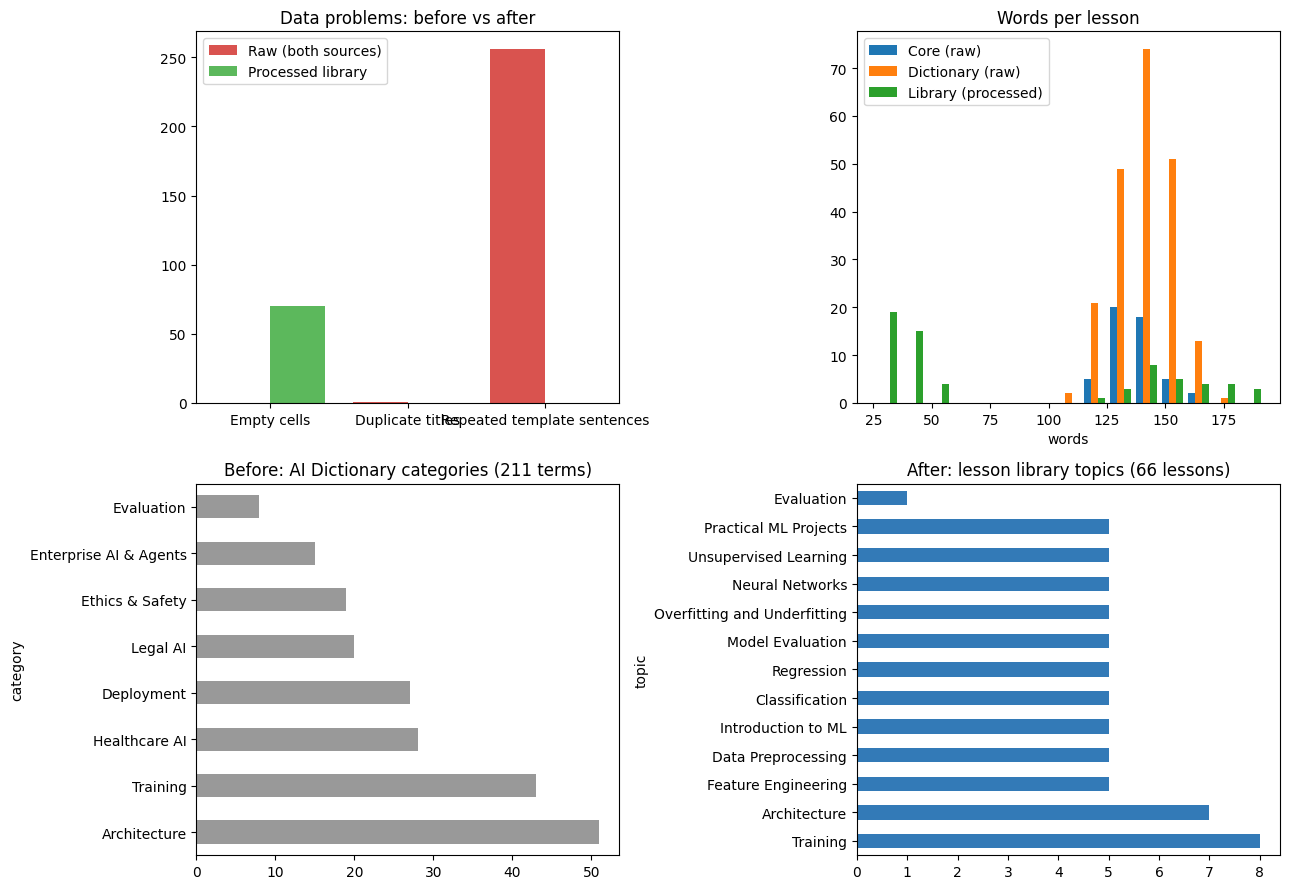


=== Sample of processed data that feeds the assistant ===


,lesson_id,title,topic,source,simple_explanation
54,55,Transfer Learning,Training,dictionary,Taking what an AI learned from one task and applying it to a different but related tas...
62,63,Hyperparameter,Training,dictionary,Settings you choose before training an AI — like how fast it learns or how many exampl...
0,1,What is Machine Learning?,Introduction to ML,core,ML learns patterns from data to make predictions.
45,46,ML Project Workflow,Practical ML Projects,core,"An ML project involves defining a problem, preparing data, training, and evaluating."
5,6,Data Cleaning,Data Preprocessing,core,"Cleaning fixes missing values, duplicates, and inconsistent records."


In [36]:
# CELL 3b — DATA QUALITY: BEFORE vs AFTER
import re, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

fig_dir = f"{project_path}/figures"
os.makedirs(fig_dir, exist_ok=True)
SKIP_COLS = {"lesson_id", "url", "search_text", "source"}   # ids, links and the search field are not lesson text

def text_columns(df):
    """All text columns that hold lesson content."""
    return [c for c in df.columns if df[c].dtype == object and c not in SKIP_COLS]

def quality_report(df):
    """Measure 5 quality numbers for one table, and return words per lesson for the histogram."""
    cols = text_columns(df)
    title_col = "title" if "title" in df.columns else "term"

    # 1) empty cells: missing (NaN) or blank text
    empty = sum(int((df[c].isna() | (df[c].astype(str).str.strip() == "")).sum()) for c in cols)

    # 2) duplicate titles: the same lesson name appears twice
    dups = int(df[title_col].astype(str).str.lower().str.strip().duplicated().sum())

    # 3) template sentences: a sentence (4+ words) copied word-for-word into 3+ lessons
    seen = Counter()
    for _, row in df[cols].iterrows():
        sents = set()
        for v in row.dropna().astype(str):
            sents |= {s.strip() for s in re.split(r"(?<=[.!?])\s+", v) if len(s.split()) >= 4}
        seen.update(sents)
    template = sum(n for n in seen.values() if n >= 3)

    # 4) words per lesson: all lesson text joined together
    words = df[cols].fillna("").astype(str).agg(" ".join, axis=1).str.split().str.len()

    return {"Rows": len(df), "Empty cells": empty, "Duplicate titles": dups,
            "Repeated template sentences": template,
            "Avg words per lesson": round(words.mean(), 1)}, words

# ---- measure the raw sources and the processed library ----
q_core, w_core = quality_report(core)          # our 50 core ML lessons (raw)
q_dict, w_dict = quality_report(lessons_raw)   # AI Dictionary, 211 terms (raw)
q_lib,  w_lib  = quality_report(lib)           # processed library, 66 lessons

quality = pd.DataFrame({"Core lessons (raw)": q_core,
                        "AI Dictionary (raw)": q_dict,
                        "Lesson library (processed)": q_lib})
print("=== Data quality: before vs after ===")
display(quality)
quality.to_csv(f"{project_path}/data/processed/data_quality_before_after.csv")

# ---- 4 charts: before vs after ----
fig, ax = plt.subplots(2, 2, figsize=(13, 9))

# Chart 1: data problems, raw vs processed (grouped bars)
m = ["Empty cells", "Duplicate titles", "Repeated template sentences"]
before = [q_core[k] + q_dict[k] for k in m]
after  = [q_lib[k] for k in m]
x = np.arange(len(m))
ax[0, 0].bar(x - 0.2, before, 0.4, label="Raw (both sources)", color="#d9534f")
ax[0, 0].bar(x + 0.2, after,  0.4, label="Processed library", color="#5cb85c")
ax[0, 0].set_xticks(x, m)
ax[0, 0].set_title("Data problems: before vs after")
ax[0, 0].legend()

# Chart 2: words per lesson (histogram)
ax[0, 1].hist([w_core, w_dict, w_lib], bins=15,
              label=["Core (raw)", "Dictionary (raw)", "Library (processed)"])
ax[0, 1].set_title("Words per lesson")
ax[0, 1].set_xlabel("words")
ax[0, 1].legend()

# Chart 3: before, AI Dictionary categories
lessons_raw["category"].value_counts().plot.barh(ax=ax[1, 0], color="#999999")
ax[1, 0].set_title(f"Before: AI Dictionary categories ({len(lessons_raw)} terms)")

# Chart 4: after, lesson library topics
lib["topic"].value_counts().plot.barh(ax=ax[1, 1], color="#337ab7")
ax[1, 1].set_title(f"After: lesson library topics ({len(lib)} lessons)")

plt.tight_layout()
plt.savefig(f"{fig_dir}/data_quality_before_after.png", dpi=150)
plt.show()

# ---- sample of processed data that feeds the assistant ----
print("\n=== Sample of processed data that feeds the assistant ===")
display(lib[["lesson_id", "title", "topic", "source", "simple_explanation"]].sample(5, random_state=42))